1. Install and import the libraries

In [5]:
# Install yfinance.
# The exclamation mark (!) tells Google Colab to run this as a system command.
%pip install -q yfinance

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
# yfinance is used to download financial data from Yahoo Finance.
import yfinance as yf

# pandas is used to organise and analyse data in tables.
import pandas as pd

# matplotlib is used to create graphs.
import matplotlib.pyplot as plt

2. Download the share prices

In [2]:
# ------------------------------------------------------------
# DOWNLOAD META'S SHARE DATA FOR THE MOST RECENT MONTH
# ------------------------------------------------------------

# Facebook's parent company is Meta Platforms.
# Its ticker symbol on the stock market is META.
ticker_symbol = "META"

# Create a yfinance Ticker object for Meta.
meta = yf.Ticker(ticker_symbol)

# Download daily share data for the most recent month.
#
# period="1mo" means the latest month of available data.
# interval="1d" means one observation for each trading day.
# auto_adjust=True adjusts prices for stock splits and dividends.
#
# Note:
# A month normally contains around 20–23 trading days because
# stock markets are closed on weekends and public holidays.
data = meta.history(
    period="1mo",
    interval="1d",
    auto_adjust=True
)

# Stop the program if Yahoo Finance does not return any data.
if data.empty:
    raise ValueError("No data were downloaded from Yahoo Finance.")

# Keep the most useful columns:
# Open   = price at the beginning of the trading day
# High   = highest price during the day
# Low    = lowest price during the day
# Close  = price at the end of the trading day
# Volume = number of shares traded during the day
data = data[["Open", "High", "Low", "Close", "Volume"]].copy()

# Display the downloaded data.
print("META share data for the most recent month:")
print(data.round(2))

META share data for the most recent month:
                             Open    High     Low   Close    Volume
Date                                                               
2026-09-24 00:00:00-04:00  744.36  779.82  743.01  777.59  34808500
2026-09-25 00:00:00-04:00  768.85  769.57  746.54  751.66  25826700
2026-09-28 00:00:00-04:00  750.04  750.58  713.19  715.62  27943100
2026-09-29 00:00:00-04:00  725.00  740.45  715.10  738.79  23591100
2026-09-30 00:00:00-04:00  730.27  738.25  721.30  725.18  19293000
2026-10-01 00:00:00-04:00  728.53  735.88  721.51  725.93  12408400
2026-10-02 00:00:00-04:00  733.25  741.58  726.20  728.08  12964100
2026-10-05 00:00:00-04:00  727.71  746.70  727.12  741.90  15215300
2026-10-06 00:00:00-04:00  746.73  747.60  736.69  738.88  12563100
2026-10-07 00:00:00-04:00  738.29  738.29  720.15  721.31  13231600
2026-10-08 00:00:00-04:00  724.54  724.95  711.68  720.89  16041100
2026-10-09 00:00:00-04:00  726.51  728.07  716.20  718.67  12619900
2026-

3. Calculate daily and cumulative profit

In [3]:
# ------------------------------------------------------------
# CALCULATE PROFIT OR LOSS
# ------------------------------------------------------------

# Assume that the investor buys one share on the first available day.
number_of_shares = 1

# iloc[0] selects the first closing price in the dataset.
# Let say we have 50 rows. The first value in Close column is
# 501. There iloc[0] will select 501.
purchase_price = data["Close"].iloc[0]

# iloc[-1] selects the latest closing price in the dataset.
# In Python, negative positions count backwards from the end:

# iloc[-1] = last value
# iloc[-2] = second-last value
# iloc[-3] = third-last value
# Let say we have 50 rows. The last value in Close column is
# 874. There iloc[-1] will select 874.
latest_price = data["Close"].iloc[-1]


# Calculate the daily price change.
#
# Formula:
# Daily profit = Today's closing price - Yesterday's closing price
#
# diff() automatically subtracts the previous row from the current row.
# For one share, the change in price is also the daily profit or loss.
data["Daily Profit ($)"] = (
    data["Close"].diff() * number_of_shares
)


# Calculate cumulative profit relative to the original purchase price.
#
# Formula:
# Cumulative profit =
# (Current price - Purchase price) × Number of shares
#
# A positive result represents profit.
# A negative result represents loss.
data["Cumulative Profit ($)"] = (
    data["Close"] - purchase_price
) * number_of_shares

# ------------------------------------------------------------
# DISPLAY THE PROFIT RESULTS
# ------------------------------------------------------------

print("DAILY AND CUMULATIVE PROFIT")
print("-" * 65)

print(f"Original purchase price: ${purchase_price:.2f}")
print(f"Number of shares: {number_of_shares}\n")

# Create a simple table containing only the information needed
# to understand the profit calculations.
profit_table = data[
    [
        "Close",
        "Daily Profit ($)",
        "Cumulative Profit ($)"
    ]
].copy()

# Round all monetary values to two decimal places.
profit_table = profit_table.round(2)

# Display the complete table.
display(profit_table)

DAILY AND CUMULATIVE PROFIT
-----------------------------------------------------------------
Original purchase price: $777.59
Number of shares: 1



,Close,Daily Profit ($),Cumulative Profit ($)
Date,,,
2026-09-24 00:00:00-04:00,777.59,NaN,0.00
2026-09-25 00:00:00-04:00,751.66,-25.93,-25.93
2026-09-28 00:00:00-04:00,715.62,-36.04,-61.97
2026-09-29 00:00:00-04:00,738.79,23.17,-38.80
2026-09-30 00:00:00-04:00,725.18,-13.61,-52.41
2026-10-01 00:00:00-04:00,725.93,0.75,-51.66
2026-10-02 00:00:00-04:00,728.08,2.15,-49.51
2026-10-05 00:00:00-04:00,741.90,13.82,-35.69
2026-10-06 00:00:00-04:00,738.88,-3.02,-38.71


4. Calculate the daily return

In [4]:
# ------------------------------------------------------------
# 4. CALCULATE AND DISPLAY DAILY RETURNS
# ------------------------------------------------------------

# Return measures the change in the share price relative to its
# previous price. It allows investors to express the change as
# a proportion or percentage.
#
# Formula:
#
#                 Today's price - Yesterday's price
# Daily return = -----------------------------------
#                        Yesterday's price


# Select the closing price from the previous trading day.
#
# shift(1) moves all closing prices down by one row.
# Therefore, each row receives the closing price from the
# previous trading day.
data["Previous Closing Price ($)"] = data["Close"].shift(1)


# METHOD 1: Calculate the daily return manually.
#
# Example:
# Yesterday's closing price = $500
# Today's closing price     = $510
#
# Daily return = ($510 - $500) / $500
#              = 0.02
#
# The decimal value 0.02 is equal to a 2% return.
data["Manual Daily Return (Decimal)"] = (
    data["Close"] - data["Previous Closing Price ($)"]
) / data["Previous Closing Price ($)"]


# METHOD 2: Calculate the daily return using pct_change(1).
#
# pct_change(1) compares each closing price with the closing
# price one row earlier. Therefore, it performs the same
# calculation as the manual formula above.
data["pct_change Daily Return (Decimal)"] = (
    data["Close"].pct_change(1)
)


# Convert the manually calculated decimal return to a percentage.
#
# Example:
# Decimal return    = 0.02
# Percentage return = 0.02 × 100 = 2%
data["Manual Daily Return (%)"] = (
    data["Manual Daily Return (Decimal)"] * 100
)


# Convert the pct_change return to a percentage.
data["pct_change Daily Return (%)"] = (
    data["pct_change Daily Return (Decimal)"] * 100
)


# ------------------------------------------------------------
# DISPLAY THE DAILY RETURN RESULTS
# ------------------------------------------------------------

# Create a simple results table containing the information
# needed to understand and compare the two return methods.
return_table = data[
    [
        "Previous Closing Price ($)",
        "Close",
        "Manual Daily Return (Decimal)",
        "pct_change Daily Return (Decimal)",
        "Manual Daily Return (%)",
        "pct_change Daily Return (%)"
    ]
].copy()


# Rename the "Close" column so that its meaning is clearer
# in the displayed table.
return_table = return_table.rename(
    columns={
        "Close": "Current Closing Price ($)"
    }
)


# Round prices to two decimal places.
return_table[
    [
        "Previous Closing Price ($)",
        "Current Closing Price ($)"
    ]
] = return_table[
    [
        "Previous Closing Price ($)",
        "Current Closing Price ($)"
    ]
].round(2)


# Round decimal returns to six decimal places.
return_table[
    [
        "Manual Daily Return (Decimal)",
        "pct_change Daily Return (Decimal)"
    ]
] = return_table[
    [
        "Manual Daily Return (Decimal)",
        "pct_change Daily Return (Decimal)"
    ]
].round(6)


# Round percentage returns to two decimal places.
return_table[
    [
        "Manual Daily Return (%)",
        "pct_change Daily Return (%)"
    ]
] = return_table[
    [
        "Manual Daily Return (%)",
        "pct_change Daily Return (%)"
    ]
].round(2)


# Print a clear title and display the complete results.
print("DAILY RETURN CALCULATIONS")
print("-" * 70)
print("Positive return = the share price increased.")
print("Negative return = the share price decreased.")
print("NaN = no previous price is available for comparison.\n")

display(return_table)

DAILY RETURN CALCULATIONS
----------------------------------------------------------------------
Positive return = the share price increased.
Negative return = the share price decreased.
NaN = no previous price is available for comparison.



,Previous Closing Price ($),Current Closing Price ($),Manual Daily Return (Decimal),pct_change Daily Return (Decimal),Manual Daily Return (%),pct_change Daily Return (%)
Date,,,,,,
2026-09-24 00:00:00-04:00,NaN,777.59,NaN,NaN,NaN,NaN
2026-09-25 00:00:00-04:00,777.59,751.66,-0.033347,-0.033347,-3.33,-3.33
2026-09-28 00:00:00-04:00,751.66,715.62,-0.047947,-0.047947,-4.79,-4.79
2026-09-29 00:00:00-04:00,715.62,738.79,0.032377,0.032377,3.24,3.24
2026-09-30 00:00:00-04:00,738.79,725.18,-0.018422,-0.018422,-1.84,-1.84
2026-10-01 00:00:00-04:00,725.18,725.93,0.001034,0.001034,0.10,0.10
2026-10-02 00:00:00-04:00,725.93,728.08,0.002962,0.002962,0.30,0.30
2026-10-05 00:00:00-04:00,728.08,741.90,0.018981,0.018981,1.90,1.90
2026-10-06 00:00:00-04:00,741.90,738.88,-0.004071,-0.004071,-0.41,-0.41


5. Calculate the complete investment result

In [5]:
# ------------------------------------------------------------
# CALCULATE THE OVERALL INVESTMENT RESULT
# ------------------------------------------------------------

# Calculate how much was originally invested.
initial_investment = purchase_price * number_of_shares

# Calculate the current value of the investment.
current_value = latest_price * number_of_shares

# Calculate the total profit or loss in dollars.
total_profit = current_value - initial_investment

# Calculate the total return as a percentage.
#
# Formula:
# Total return = (Total profit / Initial investment) × 100
total_return = (total_profit / initial_investment) * 100


# Print a simple investment summary.
print("\nINVESTMENT SUMMARY")
print("-" * 45)
print(f"Ticker:                     {ticker_symbol}")
print(f"Number of shares:           {number_of_shares}")
print(f"Purchase price:             ${purchase_price:.2f}")
print(f"Latest price:               ${latest_price:.2f}")
print(f"Initial investment:         ${initial_investment:.2f}")
print(f"Current investment value:   ${current_value:.2f}")
print(f"Total profit/loss:          ${total_profit:.2f}")
print(f"Total return:               {total_return:.2f}%")


INVESTMENT SUMMARY
---------------------------------------------
Ticker:                     META
Number of shares:           1
Purchase price:             $777.59
Latest price:               $642.62
Initial investment:         $777.59
Current investment value:   $642.62
Total profit/loss:          $-134.97
Total return:               -17.36%


6. Display the calculated results

In [7]:
# ------------------------------------------------------------
# DISPLAY THE MAIN RESULTS
# ------------------------------------------------------------
data["Manual Return"] = data["Manual Daily Return (Decimal)"]
data["pct_change Return"] = data["pct_change Daily Return (Decimal)"]
data["Daily Return (%)"] = data["Manual Daily Return (%)"]
# Create a smaller and easier-to-read results table.
results = data[
    [
        "Close",
        "Daily Profit ($)",
        "Cumulative Profit ($)",
        "Manual Return",
        "pct_change Return",
        "Daily Return (%)"
    ]
]

# Round the values to four decimal places.
print("\nDAILY RESULTS")
print("-" * 45)
print(results.round(4))


DAILY RESULTS
---------------------------------------------
                            Close  Daily Profit ($)  Cumulative Profit ($)  \
Date                                                                         
2026-09-24 00:00:00-04:00  777.59               NaN                 0.0000   
2026-09-25 00:00:00-04:00  751.66          -25.9301               -25.9301   
2026-09-28 00:00:00-04:00  715.62          -36.0400               -61.9700   
2026-09-29 00:00:00-04:00  738.79           23.1700               -38.8000   
2026-09-30 00:00:00-04:00  725.18          -13.6100               -52.4100   
2026-10-01 00:00:00-04:00  725.93            0.7500               -51.6600   
2026-10-02 00:00:00-04:00  728.08            2.1500               -49.5100   
2026-10-05 00:00:00-04:00  741.90           13.8200               -35.6900   
2026-10-06 00:00:00-04:00  738.88           -3.0200               -38.7100   
2026-10-07 00:00:00-04:00  721.31          -17.5700               -56.2800   
202

7. Compare the two return calculations

In [8]:
# ------------------------------------------------------------
# CHECK THE TWO RETURN METHODS
# ------------------------------------------------------------

# Calculate the absolute difference between the manually calculated
# returns and the returns calculated using pct_change(1).
data["Return Difference"] = abs(
    data["Manual Return"] - data["pct_change Return"]
)

# Find the largest difference.
maximum_difference = data["Return Difference"].max()

print("\nRETURN CALCULATION CHECK")
print("-" * 45)
print(f"Maximum difference: {maximum_difference:.12f}")

# Both methods should produce identical or almost identical results.
if maximum_difference < 0.0000000001:
    print("Both return methods give the same results.")
else:
    print("The two methods have a small difference.")


RETURN CALCULATION CHECK
---------------------------------------------
Maximum difference: 0.000000000000
Both return methods give the same results.


8. Plot the investment results

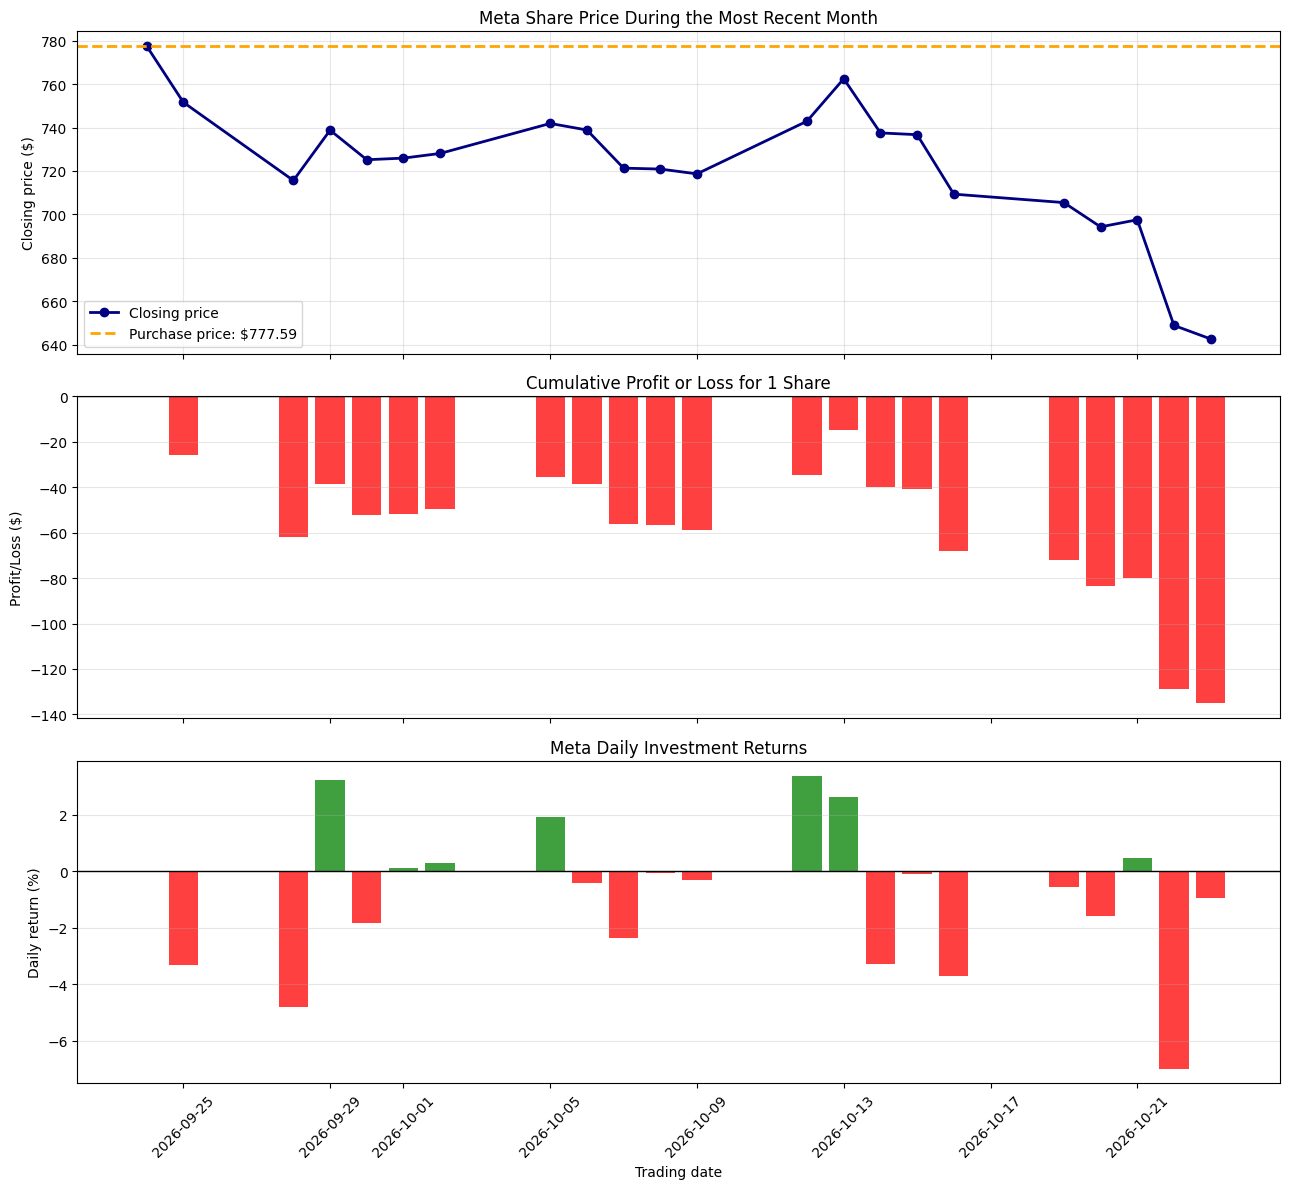

In [9]:
# ------------------------------------------------------------
# VISUALISE PRICE, PROFIT AND RETURN
# ------------------------------------------------------------

# Create three graphs arranged vertically.
#
# sharex=True means that all graphs use the same dates on the x-axis.
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 12),
    sharex=True
)


# ------------------------------------------------------------
# GRAPH 1: META CLOSING PRICE
# ------------------------------------------------------------

axes[0].plot(
    data.index,
    data["Close"],
    color="navy",
    marker="o",
    linewidth=2,
    label="Closing price"
)

# Add a horizontal line showing the original purchase price.
axes[0].axhline(
    y=purchase_price,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Purchase price: ${purchase_price:.2f}"
)

axes[0].set_title("Meta Share Price During the Most Recent Month")
axes[0].set_ylabel("Closing price ($)")
axes[0].legend()
axes[0].grid(alpha=0.3)


# ------------------------------------------------------------
# GRAPH 2: CUMULATIVE PROFIT OR LOSS
# ------------------------------------------------------------

# Select green for profit and red for loss.
profit_colours = [
    "green" if value >= 0 else "red"
    for value in data["Cumulative Profit ($)"]
]

axes[1].bar(
    data.index,
    data["Cumulative Profit ($)"],
    color=profit_colours,
    alpha=0.75
)

# Add a zero line to separate profit from loss.
axes[1].axhline(
    y=0,
    color="black",
    linewidth=1
)

axes[1].set_title(
    f"Cumulative Profit or Loss for {number_of_shares} Share"
)
axes[1].set_ylabel("Profit/Loss ($)")
axes[1].grid(axis="y", alpha=0.3)


# ------------------------------------------------------------
# GRAPH 3: DAILY PERCENTAGE RETURNS
# ------------------------------------------------------------

# Green bars show positive returns.
# Red bars show negative returns.
return_colours = [
    "green" if value >= 0 else "red"
    for value in data["Daily Return (%)"].fillna(0)
]

axes[2].bar(
    data.index,
    data["Daily Return (%)"],
    color=return_colours,
    alpha=0.75
)

# Add a zero line to separate positive and negative returns.
axes[2].axhline(
    y=0,
    color="black",
    linewidth=1
)

axes[2].set_title("Meta Daily Investment Returns")
axes[2].set_ylabel("Daily return (%)")
axes[2].set_xlabel("Trading date")
axes[2].grid(axis="y", alpha=0.3)


# Rotate the dates so that they are easier to read.
plt.xticks(rotation=45)

# Automatically improve spacing between the graphs.
plt.tight_layout()

# Display all three graphs.
plt.show()